# 03 · Modeling
**Credora Finance — Credit Risk & Loan Approval Analytics Platform**

Goal: predict, **before disbursal**, the probability that a loan will default.

The training code lives in **`src/train.py`**; this notebook runs it and explains each result.

**Method in one paragraph.** 3,403 disbursed loans are split 80/20, stratified on the target and **grouped by customer**
(no customer appears in both sets). Four models are tuned on the training set with 5-fold grouped cross-validation.
The champion is chosen by cross-validated ROC-AUC. Its probabilities are calibrated, the decision threshold is chosen on
training data only, and the **test set is used once** at the end.

Run `python src/data_load.py` first, then *Run All* (about 2 minutes).

## 1 · Train all four models

In [1]:
import sys, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 11})
pd.set_option("display.max_columns", 50, "display.width", 200)

# Works whether Jupyter was started in the project root or in notebooks/
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import train as T
import features as F
from sklearn.metrics import roc_curve, roc_auc_score, precision_recall_curve

res = T.run_training(save=True)     # same code as `python src/train.py`; also saves models/
X_train, X_test = res["X_train"], res["X_test"]
y_train, y_test = res["y_train"], res["y_test"]
p_test, thr = res["p_test"], res["threshold"]
champ = res["champion"]; M = res["metrics"]

Train: 2,721 loans (23.4% default)   Test: 682 loans (23.5% default)   [no shared customers]
  Logistic Regression  CV ROC-AUC 0.742 +/- 0.012   (15s)
  Decision Tree        CV ROC-AUC 0.710 +/- 0.017   (2s)
  Random Forest        CV ROC-AUC 0.723 +/- 0.017   (23s)
  XGBoost              CV ROC-AUC 0.731 +/- 0.014   (13s)

Champion: Logistic Regression
Decision threshold (calibrated P) = 0.226  -> recall >= 0.7 on train OOF

TEST SET (touched once)
                         ROC-AUC  Accuracy Precision  Recall     F1
  threshold 0.50           0.718     0.760     0.468   0.181  0.261
  threshold 0.23 (tuned)   0.718     0.657     0.369   0.650  0.471
  'predict nobody defaults' baseline accuracy: 0.765  (recall 0)
  PRD targets: ROC-AUC >= 0.8: NOT met  |  Recall >= 0.7: NOT met

Saved to models/: default_model.pkl, model_comparison.csv, feature_importance.csv, metrics.json
Total time: 64s


## 2 · Model comparison (cross-validation on the training set)
`cv_roc_auc` is the mean over 5 folds; `cv_auc_std` shows how much it moves between folds. Differences smaller than
about one standard deviation are **not** meaningful.

,model,cv_roc_auc,cv_auc_std,cv_recall@0.5
0,Logistic Regression,0.742,0.012,0.658
1,XGBoost,0.731,0.014,0.675
2,Random Forest,0.723,0.017,0.548
3,Decision Tree,0.710,0.017,0.746


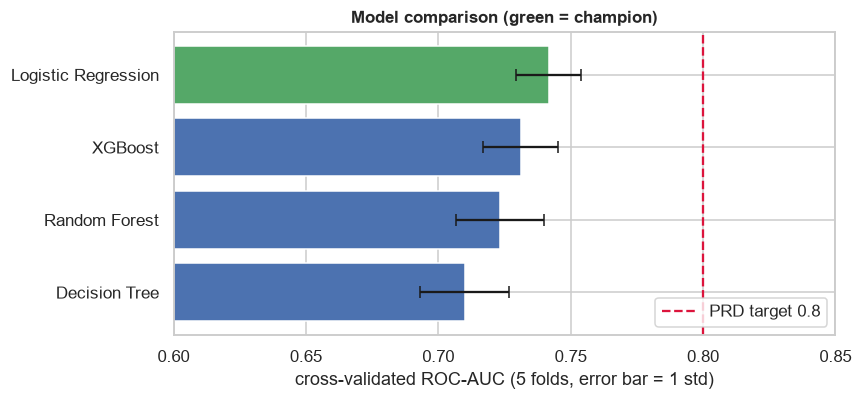

Best hyper-parameters found:
  Logistic Regression  {'C': 0.01}
  XGBoost              {'subsample': 0.7, 'n_estimators': 300, 'min_child_weight': 1, 'max_depth': 2, 'learning_rate': 0.02, 'colsample_bytree': 0.9}
  Random Forest        {'n_estimators': 300, 'min_samples_leaf': 5, 'max_features': 0.5, 'max_depth': 6}
  Decision Tree        {'min_samples_leaf': 80, 'max_depth': 6}


In [2]:
comp = res["comparison"]
display(comp.drop(columns="best_params").round(3))

fig, ax = plt.subplots(figsize=(8, 3.8))
c = comp.iloc[::-1]
ax.barh(c["model"], c["cv_roc_auc"], xerr=c["cv_auc_std"], color=["#55A868" if m == res["champion_name"] else "#4C72B0" for m in c["model"]], capsize=4)
ax.axvline(T.AUC_TARGET, color="crimson", ls="--", label=f"PRD target {T.AUC_TARGET}")
ax.set_xlim(0.6, 0.85); ax.set_xlabel("cross-validated ROC-AUC (5 folds, error bar = 1 std)")
ax.set_title("Model comparison (green = champion)"); ax.legend(loc="lower right")
plt.tight_layout(); plt.show()
print("Best hyper-parameters found:")
for _, r in comp.iterrows():
    print(f"  {r['model']:<20} {r['best_params']}")

The four models land within a few points of each other. When a simple model matches the complex ones, it is the better
choice: it is faster, easier to explain to a credit committee, and less likely to overfit 3,400 rows.

## 3 · ROC curves on the held-out test set
The champion was already chosen by cross-validation above; the test curves are shown only so you can see the models
side by side.

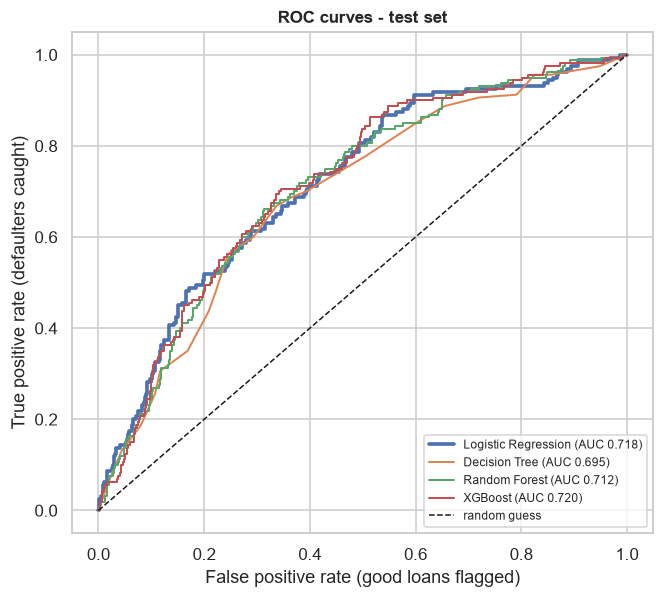

In [3]:
fig, ax = plt.subplots(figsize=(6.2, 5.6))
for name, rs in res["searches"].items():
    p = rs.best_estimator_.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, p)
    ax.plot(fpr, tpr, lw=2.4 if name == res["champion_name"] else 1.3,
            label=f"{name} (AUC {roc_auc_score(y_test, p):.3f})")
ax.plot([0, 1], [0, 1], "k--", lw=1, label="random guess")
ax.set_xlabel("False positive rate (good loans flagged)"); ax.set_ylabel("True positive rate (defaulters caught)")
ax.set_title("ROC curves - test set"); ax.legend(loc="lower right", fontsize=8)
plt.tight_layout(); plt.show()

## 4 · Calibration: making probabilities honest
We trained with class weights so the model would pay attention to the rare defaulters. That inflates raw probabilities,
so a "70%" would not mean 70%. **Platt scaling** (fitted on out-of-fold training predictions) fixes this. On the test set,
the predicted default rate should match the actual rate in each group:

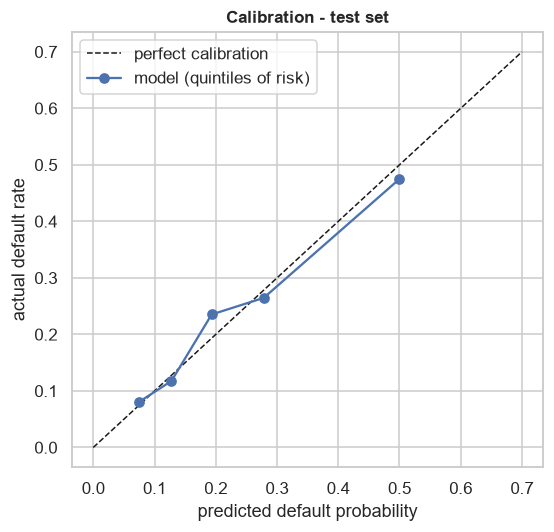

Mean predicted default rate: 23.5%   Actual: 23.5%


In [4]:
cal = pd.DataFrame({"p": p_test, "y": y_test.to_numpy()})
cal["bin"] = pd.qcut(cal["p"], 5, duplicates="drop")
t = cal.groupby("bin", observed=True).agg(predicted=("p", "mean"), actual=("y", "mean"), loans=("y", "size"))
fig, ax = plt.subplots(figsize=(5.2, 5))
ax.plot([0, 0.7], [0, 0.7], "k--", lw=1, label="perfect calibration")
ax.plot(t["predicted"], t["actual"], "o-", color="#4C72B0", label="model (quintiles of risk)")
ax.set_xlabel("predicted default probability"); ax.set_ylabel("actual default rate"); ax.legend()
ax.set_title("Calibration - test set")
plt.tight_layout(); plt.show()
print(f"Mean predicted default rate: {p_test.mean() * 100:.1f}%   Actual: {y_test.mean() * 100:.1f}%")

## 5 · Choosing the decision threshold
At the default 0.5 cut-off almost nobody is flagged, because only 23% of loans default. The PRD asks for **recall ≥ 0.70**
(catch at least 70% of defaulters). So the threshold is the **highest** one that still reaches that recall on the training
data's out-of-fold predictions; the test set plays no part in choosing it.

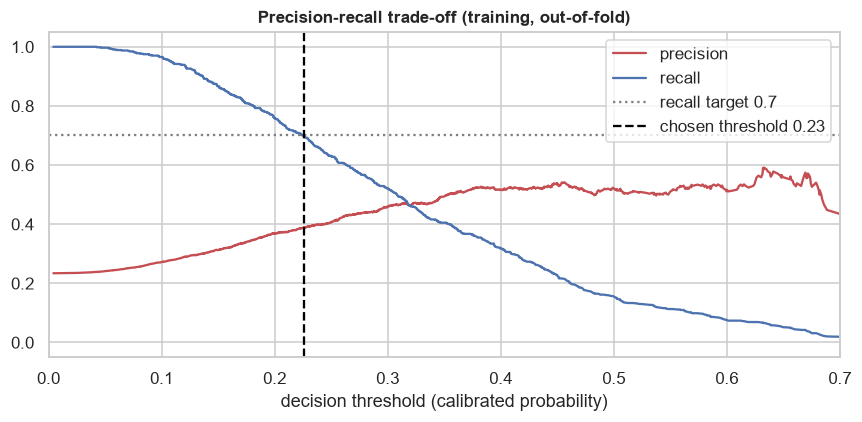

In [5]:
prec, rec, th = precision_recall_curve(y_train, res["oof_train_cal"])
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(th, prec[:-1], label="precision", color="#C44E52")
ax.plot(th, rec[:-1], label="recall", color="#4C72B0")
ax.axhline(T.RECALL_TARGET, color="grey", ls=":", label=f"recall target {T.RECALL_TARGET}")
ax.axvline(thr, color="black", ls="--", label=f"chosen threshold {thr:.2f}")
ax.set_xlabel("decision threshold (calibrated probability)"); ax.set_xlim(0, 0.7); ax.legend()
ax.set_title("Precision-recall trade-off (training, out-of-fold)")
plt.tight_layout(); plt.show()

**The trade-off is a business decision.** A lower threshold catches more defaulters (higher recall) but also flags more good
borrowers (lower precision). Rejecting a good customer costs lost interest; approving a defaulter costs the principal.

## 6 · Final test-set results (used once)

,ROC-AUC,accuracy,precision,recall,F1
setting,,,,,
threshold 0.50 (default),0.718,0.760,0.468,0.181,0.261
threshold 0.23 (tuned),0.718,0.657,0.369,0.650,0.471


Baseline 'predict nobody defaults': accuracy 0.765, recall 0.  Accuracy alone is misleading here.


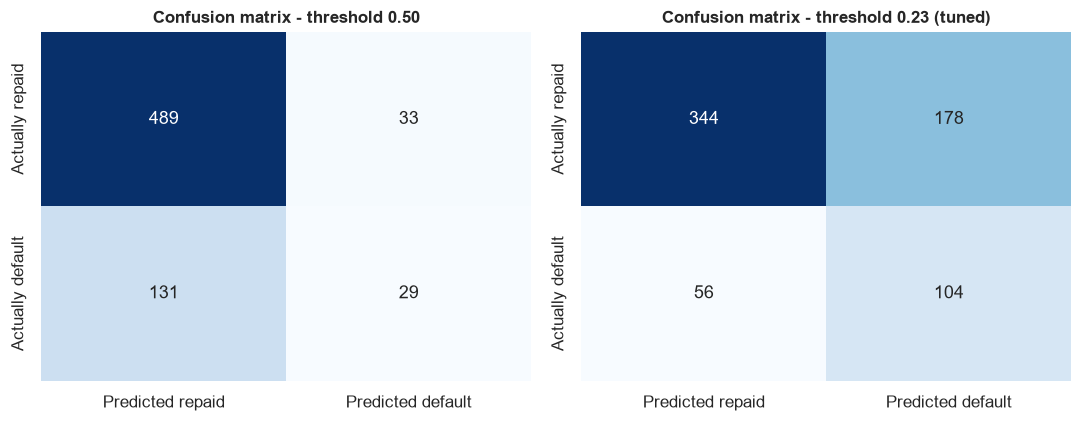

In [6]:
rows = []
for label, key in [("threshold 0.50 (default)", "test_at_0.5"), (f"threshold {thr:.2f} (tuned)", "test_at_tuned_threshold")]:
    m = M[key]
    rows.append({"setting": label, "ROC-AUC": m["roc_auc"], "accuracy": m["accuracy"], "precision": m["precision"],
                 "recall": m["recall"], "F1": m["f1"]})
display(pd.DataFrame(rows).round(3).set_index("setting"))
print(f"Baseline 'predict nobody defaults': accuracy {M['baseline_accuracy']:.3f}, recall 0.  Accuracy alone is misleading here.")

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (label, key) in zip(axes, [("threshold 0.50", "test_at_0.5"), (f"threshold {thr:.2f} (tuned)", "test_at_tuned_threshold")]):
    m = M[key]
    sns.heatmap(np.array([[m["tn"], m["fp"]], [m["fn"], m["tp"]]]), annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Predicted repaid", "Predicted default"], yticklabels=["Actually repaid", "Actually default"])
    ax.set_title(f"Confusion matrix - {label}")
plt.tight_layout(); plt.show()

### Against the PRD success targets

In [7]:
m = M["test_at_tuned_threshold"]
rng = np.random.default_rng(42)
yt, pt = y_test.to_numpy(), p_test
aucs, recs = [], []
for _ in range(2000):
    i = rng.integers(0, len(yt), len(yt))
    if yt[i].sum() == 0:
        continue
    aucs.append(roc_auc_score(yt[i], pt[i]))
    recs.append(((pt[i] >= thr) & (yt[i] == 1)).sum() / yt[i].sum())
lo_a, hi_a = np.percentile(aucs, [2.5, 97.5]); lo_r, hi_r = np.percentile(recs, [2.5, 97.5])

print(f"ROC-AUC : {m['roc_auc']:.3f}   95% interval [{lo_a:.3f}, {hi_a:.3f}]   target >= {T.AUC_TARGET}   -> {'MET' if m['roc_auc'] >= T.AUC_TARGET else 'NOT met'}")
print(f"Recall  : {m['recall']:.3f}   95% interval [{lo_r:.3f}, {hi_r:.3f}]   target >= {T.RECALL_TARGET}   -> {'MET' if m['recall'] >= T.RECALL_TARGET else 'NOT met'}")
if lo_r <= T.RECALL_TARGET <= hi_r:
    print(f"(Recall: the {T.RECALL_TARGET} target lies INSIDE the 95% interval, so this test set cannot tell us whether it is truly missed.)")
if hi_a < T.AUC_TARGET:
    print(f"(ROC-AUC: the {T.AUC_TARGET} target lies ABOVE the whole 95% interval, so it is genuinely not reached.)")
print(f"\nTest set has only {len(yt)} loans ({int(yt.sum())} defaults), so results carry roughly +/- {100 * (hi_a - lo_a) / 2:.0f} AUC points of noise.")

ROC-AUC : 0.718   95% interval [0.674, 0.761]   target >= 0.8   -> NOT met
Recall  : 0.650   95% interval [0.577, 0.720]   target >= 0.7   -> NOT met
(Recall: the 0.7 target lies INSIDE the 95% interval, so this test set cannot tell us whether it is truly missed.)
(ROC-AUC: the 0.8 target lies ABOVE the whole 95% interval, so it is genuinely not reached.)

Test set has only 682 loans (160 defaults), so results carry roughly +/- 4 AUC points of noise.


**Reading this honestly.** The test set is small, so every number has a wide uncertainty band (the 95% intervals above).
The AUC target of 0.80 falls outside the interval, so it is not a matter of bad luck on this split. See section 9 for why.
The recall target is near the edge: the threshold reached 70% on the training folds, and the test result lands within
noise of it.

## 7 · What drives the prediction?

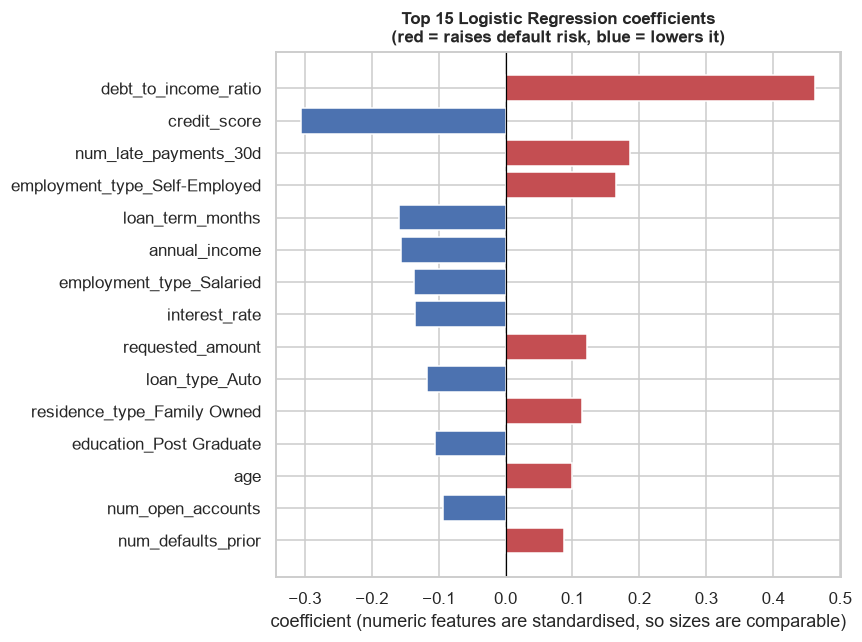

,feature,importance,importance_pct,method
0,debt_to_income_ratio,0.463,12.677,abs(coefficient)
1,credit_score,0.305,8.356,abs(coefficient)
2,num_late_payments_30d,0.186,5.104,abs(coefficient)
3,employment_type_Self-Employed,0.165,4.516,abs(coefficient)
4,loan_term_months,0.160,4.376,abs(coefficient)
5,annual_income,0.156,4.280,abs(coefficient)
6,employment_type_Salaried,0.137,3.743,abs(coefficient)
7,interest_rate,0.136,3.721,abs(coefficient)
8,requested_amount,0.121,3.321,abs(coefficient)
9,loan_type_Auto,0.118,3.228,abs(coefficient)


In [8]:
est = champ.named_steps["model"]; names = champ.named_steps["prep"].get_feature_names_out()
if hasattr(est, "coef_"):
    coef = pd.Series(est.coef_.ravel(), index=names)
    top = coef.reindex(coef.abs().sort_values(ascending=False).head(15).index).iloc[::-1]
    fig, ax = plt.subplots(figsize=(8, 6))
    ax.barh(top.index, top.values, color=["#C44E52" if v > 0 else "#4C72B0" for v in top.values])
    ax.axvline(0, color="black", lw=0.8)
    ax.set_title("Top 15 Logistic Regression coefficients\n(red = raises default risk, blue = lowers it)")
    ax.set_xlabel("coefficient (numeric features are standardised, so sizes are comparable)")
    plt.tight_layout(); plt.show()
else:
    imp = res["importance"].head(15).iloc[::-1]
    fig, ax = plt.subplots(figsize=(8, 6)); ax.barh(imp["feature"], imp["importance_pct"], color="#4C72B0")
    ax.set_title("Top 15 feature importances (%)"); plt.tight_layout(); plt.show()
res["importance"].head(10).round(3)

### SHAP: explanation per feature and per applicant
SHAP assigns each feature a contribution to each prediction. The first chart summarises the whole test set; the second
explains one specific applicant — the type of explanation a credit officer would want.

*Two cautions.* SHAP values are on the model's raw log-odds scale, **before** calibration, so the numbers in the second chart
do not equal the calibrated percentage in its title. And effects are *conditional associations*, not causes: for example,
higher interest rates are linked here to **lower** default risk, the opposite of pricing logic. That is probably a loan-type
mix effect in this synthetic dataset (not verified), and it is a reason not to read coefficients as advice.

Background dataset has 2721 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=2721 when initializing the masker.


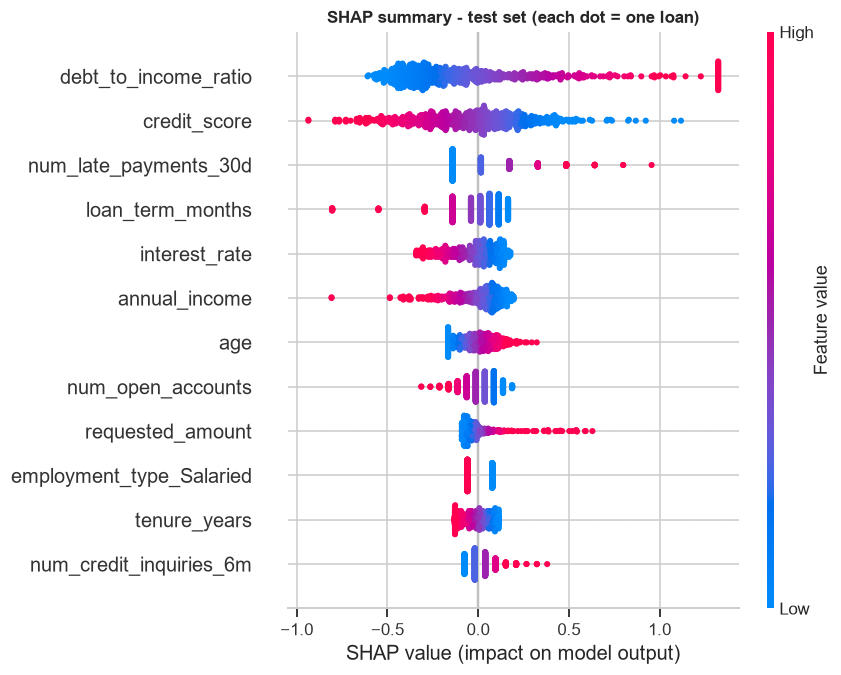

In [9]:
import shap
prep = champ.named_steps["prep"]
Xtr_t, Xte_t = prep.transform(X_train), prep.transform(X_test)
try:
    if hasattr(est, "coef_"):
        expl = shap.LinearExplainer(est, Xtr_t); sv = expl.shap_values(Xte_t); base = float(np.ravel(expl.expected_value)[0])
    else:
        expl = shap.TreeExplainer(est); sv = expl.shap_values(Xte_t)
        if isinstance(sv, list): sv = sv[1]
        if getattr(sv, "ndim", 2) == 3: sv = sv[:, :, 1]
        base = float(np.ravel(expl.expected_value)[-1])
    shap.summary_plot(sv, Xte_t, max_display=12, show=False)
    plt.title("SHAP summary - test set (each dot = one loan)"); plt.tight_layout(); plt.show()
except Exception as e:
    sv = None
    print("SHAP summary unavailable in this environment:", type(e).__name__, str(e)[:120])

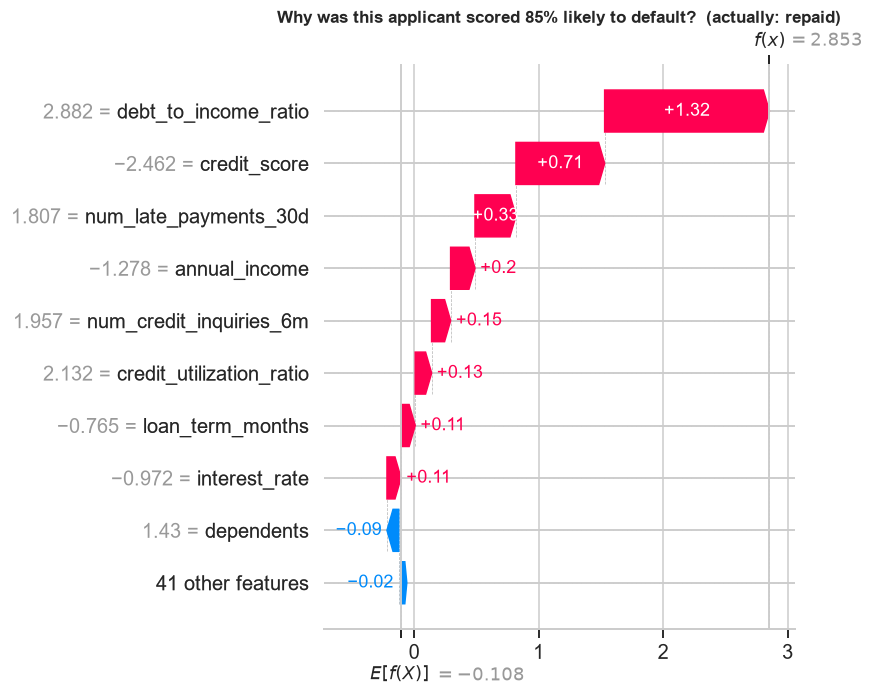

In [10]:
if sv is not None:
    i = int(np.argmax(p_test))   # the test applicant with the highest predicted risk
    exp = shap.Explanation(values=sv[i], base_values=base, data=Xte_t.iloc[i].values, feature_names=list(Xte_t.columns))
    shap.plots.waterfall(exp, max_display=10, show=False)
    plt.title(f"Why was this applicant scored {p_test[i] * 100:.0f}% likely to default?  (actually: {'defaulted' if y_test.iloc[i] else 'repaid'})")
    plt.tight_layout(); plt.show()

## 8 · Why is ROC-AUC below the 0.80 target?

In [11]:
dti = X_train["debt_to_income_ratio"].fillna(X_train["debt_to_income_ratio"].median())
cs = X_train["credit_score"].fillna(X_train["credit_score"].median())
orient = lambda a: max(a, 1 - a)    # higher credit score means LESS default, so flip the direction
print(f"Best single feature (debt-to-income) alone : AUC {orient(roc_auc_score(y_train, dti)):.3f}")
print(f"Credit score alone                         : AUC {orient(roc_auc_score(y_train, cs)):.3f}")
print(f"All 34 features, tuned champion (CV)       : AUC {res['comparison'].loc[0, 'cv_roc_auc']:.3f}")
print(f"Best of the four models (CV)               : AUC {res['comparison']['cv_roc_auc'].max():.3f}")

from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, StratifiedGroupKFold, cross_val_score
g_train = res["groups"].iloc[res["train_idx"]]
rand = cross_val_score(clone(champ), X_train, y_train, cv=StratifiedKFold(5, shuffle=True, random_state=42), scoring="roc_auc").mean()
grp = cross_val_score(clone(champ), X_train, y_train, cv=StratifiedGroupKFold(5, shuffle=True, random_state=42), groups=g_train, scoring="roc_auc").mean()
print(f"\nChampion CV AUC, random row split: {rand:.3f}   vs   split by customer: {grp:.3f}")
print("If these two are close, the validation scheme is not what holds the score down: the ceiling is in the data.")

Best single feature (debt-to-income) alone : AUC 0.686
Credit score alone                         : AUC 0.656
All 34 features, tuned champion (CV)       : AUC 0.742
Best of the four models (CV)               : AUC 0.742

Champion CV AUC, random row split: 0.743   vs   split by customer: 0.742
If these two are close, the validation scheme is not what holds the score down: the ceiling is in the data.


Each feature adds a little and together they reach about 0.74, but no combination approaches 0.80. Four honest reasons:

1. **Limited signal in the data.** Individual features are only moderately predictive, and complex models do not find hidden structure that a simple one misses (Logistic Regression, XGBoost and Random Forest are within about one standard deviation of each other).
2. **Small sample.** 3,403 labelled loans, about 800 defaults.
3. **Thin transaction history.** Only about 8 transactions per customer over 6 months.
4. **Timing.** Bureau and transaction data are from 2024, while many loans were disbursed in 2022. In a real bank this would be a timing problem; here it adds noise.

**What we report:** ROC-AUC around 0.72-0.74 with its uncertainty, recall tuned to the target through the threshold, and a clear
statement that the PRD's 0.80 AUC target was not reached on this dataset. That is a credible result; a forced 0.80 would not be.

## 9 · Summary
- **Champion:** chosen by cross-validated ROC-AUC, fitted on the training set, calibrated, threshold set on training data.
- **Saved to `models/`:** `default_model.pkl` (pipeline + calibrator + threshold + metadata), `model_comparison.csv`,
  `feature_importance.csv`, `metrics.json`.
- **Next:** `src/risk_score.py` converts calibrated probabilities into the 0-100 score and Low / Medium / High labels,
  and `04_risk_scoring.ipynb` validates them.